In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("C:\\Users\\ABHINAV AR\\data.csv")

df.head()

,date,atm_id,city,cash_withdrawals,avg_transaction_amount,cash_demand_lakh,is_weekend,day_of_month,month,day_of_week
0,2024-01-01,ATM_001,Bengaluru,482,2624.0,12.65,0,1,1,0
1,2024-01-02,ATM_001,Bengaluru,460,2873.0,13.22,0,2,1,1
2,2024-01-03,ATM_001,Bengaluru,488,2494.0,12.17,0,3,1,2
3,2024-01-04,ATM_001,Bengaluru,519,2985.0,15.49,0,4,1,3
4,2024-01-05,ATM_001,Bengaluru,457,2885.0,13.18,0,5,1,4


In [10]:
df.shape

df.info()

df.describe()

df.isnull().sum()

df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    731 non-null    object 
 1   atm_id                  731 non-null    object 
 2   city                    731 non-null    object 
 3   cash_withdrawals        731 non-null    int64  
 4   avg_transaction_amount  719 non-null    float64
 5   cash_demand_lakh        731 non-null    float64
 6   is_weekend              731 non-null    int64  
 7   day_of_month            731 non-null    int64  
 8   month                   731 non-null    int64  
 9   day_of_week             731 non-null    int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 57.2+ KB


0

In [12]:
df["avg_transaction_amount"] = df["avg_transaction_amount"].fillna(
    df["avg_transaction_amount"].median()
)

df["date"] = pd.to_datetime(df["date"])

df.isnull().sum()

date                      0
atm_id                    0
city                      0
cash_withdrawals          0
avg_transaction_amount    0
cash_demand_lakh          0
is_weekend                0
day_of_month              0
month                     0
day_of_week               0
dtype: int64

In [15]:
df = df.sort_values("date")

df["next_day_cash_demand"] = df["cash_demand_lakh"].shift(-1)

df = df.dropna()
df.head()


,date,atm_id,city,cash_withdrawals,avg_transaction_amount,cash_demand_lakh,is_weekend,day_of_month,month,day_of_week,next_day_cash_demand
0,2024-01-01,ATM_001,Bengaluru,482,2624.0,12.65,0,1,1,0,13.22
1,2024-01-02,ATM_001,Bengaluru,460,2873.0,13.22,0,2,1,1,12.17
2,2024-01-03,ATM_001,Bengaluru,488,2494.0,12.17,0,3,1,2,15.49
3,2024-01-04,ATM_001,Bengaluru,519,2985.0,15.49,0,4,1,3,13.18
4,2024-01-05,ATM_001,Bengaluru,457,2885.0,13.18,0,5,1,4,13.72


In [18]:
X = df.drop(columns=[
    "date",
    "atm_id",
    "city",
    "cash_demand_lakh",
    "next_day_cash_demand"
])

y = df["next_day_cash_demand"]

X.head()
y.head()

0    13.22
1    12.17
2    15.49
3    13.18
4    13.72
Name: next_day_cash_demand, dtype: float64

In [19]:
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (584, 6)
Testing data: (146, 6)


In [20]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [21]:
y_pred = model.predict(X_test)

print("Actual Cash Demand:")
print(y_test.head())

print("\nPredicted Cash Demand:")
print(y_pred[:5])

Actual Cash Demand:
584    11.87
585    13.75
586    13.10
587    13.17
588    11.72
Name: next_day_cash_demand, dtype: float64

Predicted Cash Demand:
[12.2827 14.138  14.143  12.5564 12.6719]


In [26]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

MAE: 1.4013205479452056
MSE: 3.4743821895890417
R2 Score: 0.39611233725089956


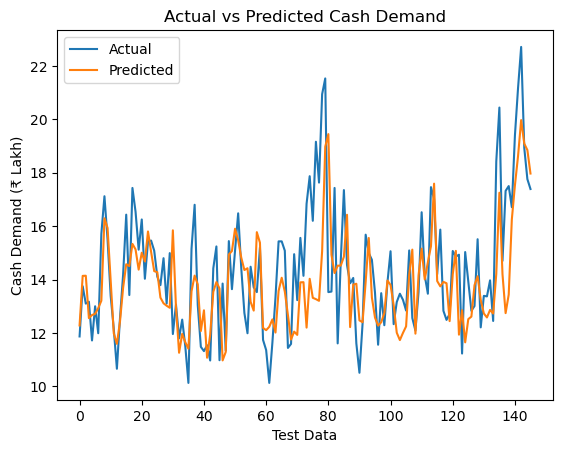

In [27]:
plt.plot(y_test.values, label="Actual")
plt.plot(y_pred, label="Predicted")

plt.title("Actual vs Predicted Cash Demand")
plt.xlabel("Test Data")
plt.ylabel("Cash Demand (₹ Lakh)")

plt.legend()
plt.show()

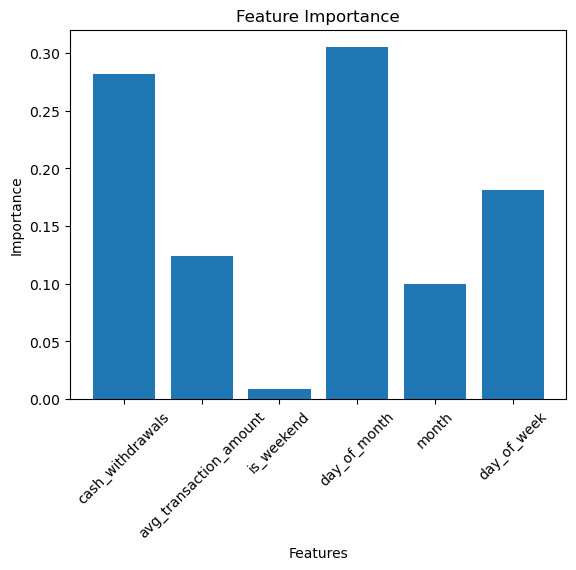

In [28]:
plt.bar(X.columns, model.feature_importances_)

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.xticks(rotation=45)
plt.show()

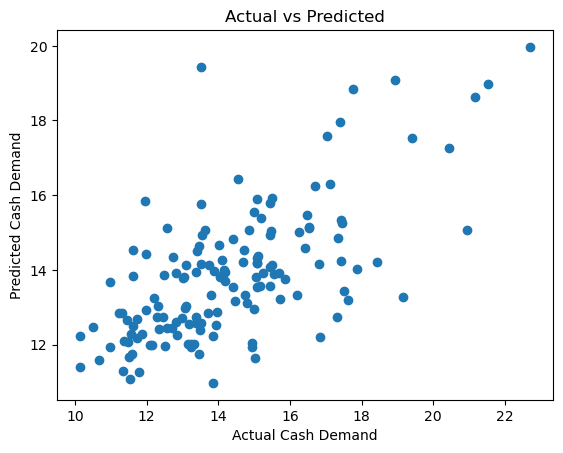

In [29]:
plt.scatter(y_test, y_pred)

plt.title("Actual vs Predicted")
plt.xlabel("Actual Cash Demand")
plt.ylabel("Predicted Cash Demand")

plt.show()